# Reproducibilidad, autoría y uso de herramientas

En este capítulo reunimos lo necesario para regenerar cada tabla y figura del libro: el comando único, el entorno, las semillas, el *hardware*, el tiempo de cómputo y la huella de carbono. Al final declaramos cómo usamos herramientas de inteligencia artificial y cómo verificamos su trabajo.

In [1]:
import platform
import re

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, style
from project.config import RESULTS, ROOT
from project.persist import load_pickle

style()
pd.set_option("display.precision", 2)
md = lambda t: display(Markdown(t))  # noqa: E731

## Comando único

```bash
python -m venv .venv && .venv/Scripts/pip install -r requirements.lock && .venv/Scripts/pip install -e .
export KAGGLE_API_TOKEN=...        # reglas aceptadas en las dos competencias
make reproduce                     # data → splits → queue → eval → analysis → track → book
```

| Etapa | Comando | Qué produce |
|---|---|---|
| Datos | `make data` | descarga de Kaggle y verificación SHA-256 (`data/SHA256SUMS.txt`) |
| Particiones | `make splits` | caché de etiquetas y particiones; aborta si la partición reconstruida difiere de la guardada |
| Entrenamiento | `make queue` | todos los trabajos de `configs/queue.yaml`, en orden, reanudables; cada uno marca `DONE` al terminar |
| Evaluación | `make eval` | selección del posproceso en validación y evaluación única de test (segmentación) |
| Análisis | `make analysis` | EDA, estadística, figuras e índice de pickles |
| Seguimiento | `make track` | volcado de `results/` a MLflow y registro de modelos |
| Libro | `make book` | notebooks generados desde `book/nb_src/` y libro compilado en `book/_build/html` |

Cada resultado se escribe en un pickle de `results/` con escritura atómica (archivo temporal y renombrado), y los notebooks solo leen pickles: si falta uno, la celda indica el comando que lo genera. El índice completo de pickles está en `results/INDICE_PICKLES.md`. `dvc repro` ejecuta las mismas etapas y solo rehace las que cambiaron.

## Entorno y *hardware*

In [2]:
env = {"Sistema operativo": f"{platform.system()} {platform.release()}", "Python": platform.python_version(),
       "Procesador": platform.processor() or "—"}
try:
    import torch

    env["PyTorch"] = torch.__version__
    env["CUDA"] = torch.version.cuda or "—"
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        env["GPU"] = f"{p.name}, {p.total_memory / 1e9:.1f} GB"
except Exception:  # noqa: BLE001
    pass
try:
    import psutil

    env["RAM"] = f"{psutil.virtual_memory().total / 1e9:.0f} GB"
    env["Núcleos (físicos / lógicos)"] = f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count()}"
except Exception:  # noqa: BLE001
    pass
lock = (ROOT / "requirements.lock").read_text(encoding="utf-8").splitlines()
key = ["keras", "torch", "torchvision", "transformers", "scikit-learn", "xgboost", "fasttext", "gensim", "optuna", "cellpose",
       "segment-anything", "onnx", "onnxruntime", "fastapi", "mlflow", "dvc", "codecarbon", "statsmodels", "scipy", "numpy", "pandas"]
ver = {}
for line in lock:
    m_ = re.match(r"^([A-Za-z0-9_.\-]+)==(.+)$", line.strip())
    if m_ and m_.group(1).lower() in key:
        ver[m_.group(1).lower()] = m_.group(2)
display(pd.DataFrame({"valor": env}))
display(pd.DataFrame({"versión": ver}).sort_index())
md(f"`requirements.lock` fija las {sum(1 for x in lock if '==' in x)} dependencias del entorno de entrenamiento y `requirements-serve.lock` las de la imagen de servicio.")

,valor
Sistema operativo,Windows 11
Python,3.12.10
Procesador,"AMD64 Family 25 Model 117 Stepping 2, Authenti..."
PyTorch,2.15.0+cu132
CUDA,13.2
RAM,34 GB
Núcleos (físicos / lógicos),8 / 16


,versión
cellpose,3.1.1.3
codecarbon,3.3.3
dvc,3.67.1
fastapi,0.165.0
gensim,4.4.0
keras,3.15.1
numpy,2.0.2
onnx,1.23.2
onnxruntime,1.32.0
optuna,5.1.0


`requirements.lock` fija las 323 dependencias del entorno de entrenamiento y `requirements-serve.lock` las de la imagen de servicio.

## Semillas y determinismo

| Elemento | Semilla |
|---|---|
| Partición de Sartorius (`StratifiedGroupKFold`, 20 pliegues) | 42 |
| Partición de Jarvis (`StratifiedGroupKFold` por grupos de casi duplicados) | 42 |
| MinHash de casi duplicados | 1 |
| Modelos de segmentación | 0, 1, 2 (ablaciones: las que entraron en el presupuesto, ver capítulo {doc}`14_seg_ablaciones_robustez`) |
| Modelos de texto | 0, 1, 2, 3, 4 (búsqueda de hiperparámetros: semilla 0) |
| Muestras aleatorias de figuras, conjuntos dorados y ventanas de deriva | 2026 o 0, fijadas en el código |

`set_global_seed` fija Python, NumPy y PyTorch. No activamos los algoritmos deterministas de cuDNN porque ralentizan las convoluciones; la variación residual entre ejecuciones con la misma semilla queda dentro de la variación entre semillas, que reportamos siempre. La prueba `test_seed_determinism` verifica que la misma semilla reproduce las mismas muestras aleatorias.

## Tiempo de cómputo

,trabajos,minutos,horas
bloque,,,
MLOps,4,27.6,0.46
otros,2,20.6,0.34
segmentación,32,1336.5,22.27
texto,37,602.6,10.04


Tiempo total de la cola de entrenamiento: 33.1 h en 75 trabajos, del 2026-11-25 08:15 al 2026-11-26 16:26. Los trabajos fallidos y reintentados están en `results/queue/queue.log`.

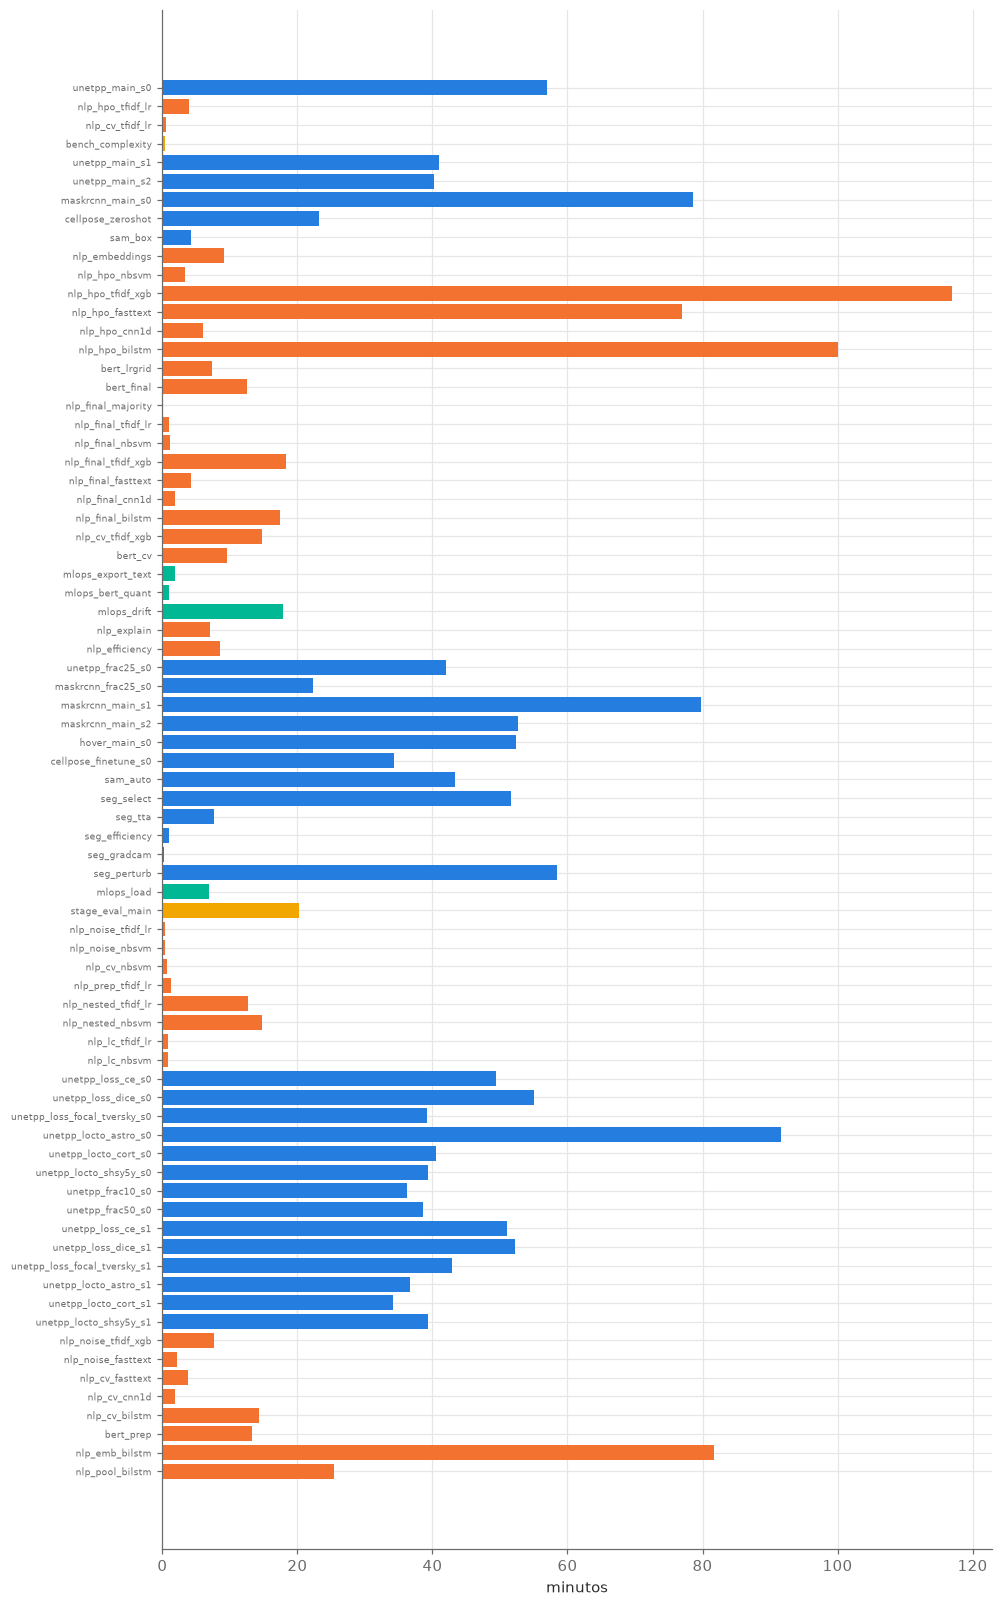

In [3]:
st = load_pickle(RESULTS / "queue" / "state.pkl")
runs = pd.DataFrame(st["runs"])
runs = runs[runs.ok]


def block(j: str) -> str:
    if j.startswith(("unetpp", "maskrcnn", "hover", "cellpose", "sam", "seg_", "otsu")):
        return "segmentación"
    if j.startswith(("nlp", "bert")):
        return "texto"
    if j.startswith("mlops"):
        return "MLOps"
    return "otros"


runs["bloque"] = runs.job.map(block)
tb = runs.groupby("bloque").minutes.agg(["count", "sum"]).rename(columns={"count": "trabajos", "sum": "minutos"})
tb["horas"] = tb.minutos / 60
display(tb.round({"minutos": 1, "horas": 2}))
md(f"Tiempo total de la cola de entrenamiento: {runs.minutes.sum() / 60:.1f} h en {len(runs)} trabajos, del "
   f"{runs.end.min()[:16]} al {runs.end.max()[:16]}. Los trabajos fallidos y reintentados están en `results/queue/queue.log`.")
fig, ax = plt.subplots(figsize=(9, 0.18 * len(runs) + 1))
ax.barh(runs.job, runs.minutes, color=[CAT[["segmentación", "texto", "MLOps", "otros"].index(b)] for b in runs.bloque])
ax.invert_yaxis(); ax.set(xlabel="minutos"); ax.tick_params(axis="y", labelsize=6)
plt.show()

## Huella de carbono

El monitor de `codecarbon` {cite:p}`codecarbon2024` midió la energía del equipo completo (CPU, GPU y RAM) en ventanas consecutivas durante la primera parte del proyecto, con el factor de emisión de Colombia. Se detuvo cuando el sistema lo cerró por falta de memoria al iniciar Mask R-CNN. Para el resto del tiempo de cómputo estimamos la energía como potencia media medida × duración de los trabajos, una estimación de orden de magnitud.

In [4]:
cols = ["start", "end", "seconds", "cpu_kwh", "gpu_kwh", "ram_kwh", "total_kwh", "kg_co2eq", "cpu_w", "gpu_w"]
ew = pd.read_csv(RESULTS / "mlops" / "energy_windows.csv", names=cols)
ew = ew[pd.to_numeric(ew.seconds, errors="coerce").notna()].astype({c: float for c in cols[2:]})
measured_h = ew.seconds.sum() / 3600
kw = ew.total_kwh.sum() / measured_h
factor = ew.kg_co2eq.sum() / ew.total_kwh.sum()
total_h = runs.minutes.sum() / 60
unmeasured_h = max(total_h - measured_h, 0)
tab = pd.DataFrame([
    dict(periodo="medido por codecarbon", horas=measured_h, kWh=ew.total_kwh.sum(), **{"kg CO₂eq": ew.kg_co2eq.sum()}),
    dict(periodo="estimado (potencia media × duración)", horas=unmeasured_h, kWh=kw * unmeasured_h, **{"kg CO₂eq": kw * unmeasured_h * factor})])
tab.loc[len(tab)] = dict(periodo="total", horas=tab.horas.sum(), kWh=tab.kWh.sum(), **{"kg CO₂eq": tab["kg CO₂eq"].sum()})
display(tab.style.hide(axis="index").format(precision=3))
md(f"Potencia media medida: {1e3 * kw:.0f} W. Factor de emisión: {1e3 * factor:.0f} g CO₂eq/kWh. La estimación no incluye el cómputo fuera "
   f"de la cola (análisis, notebooks, pruebas) ni la fabricación del equipo.")

periodo,horas,kWh,kg CO₂eq
medido por codecarbon,1.522,0.132,0.025
estimado (potencia media × duración),31.599,2.747,0.513
total,33.122,2.879,0.538


Potencia media medida: 87 W. Factor de emisión: 187 g CO₂eq/kWh. La estimación no incluye el cómputo fuera de la cola (análisis, notebooks, pruebas) ni la fabricación del equipo.

## Desviaciones del protocolo

Todas las desviaciones del pre-registro (`results/common/preregistro_2026-11-25.md`, etiqueta git `prereg`) están en la tabla del capítulo {doc}`03_declaracion_apriori` y, con fecha, hora y motivo, en la bitácora del proyecto (`reports/bitacora.md`).

## Autoría y uso de herramientas de inteligencia artificial

Usamos Claude Code (Anthropic), un asistente de programación basado en un modelo de lenguaje, durante todo el proyecto.

**Qué hizo el asistente.** A partir del enunciado y de nuestros documentos de instrucciones, escribió la mayor parte del código del paquete `src/project/`, los *scripts*, la API, las pruebas, la configuración de CI y el `Makefile`; redactó el pre-registro a partir de las hipótesis del enunciado antes de entrenar; ejecutó la cola de entrenamiento; registró sus decisiones operativas en la bitácora, y escribió los borradores de los capítulos.

**Qué hicimos los autores.** Fijamos el alcance, las restricciones y las reglas de trabajo en documentos de instrucciones (qué priorizar, qué no hacer, plazos y estilo); preparamos el entorno y los datos; resolvimos a mano los ejercicios teóricos; anotamos a mano los errores de clasificación para la medida de concordancia, y revisamos cada capítulo y cada cifra antes de la entrega.

**Cómo verificamos el trabajo.**

- Ninguna cifra del libro está escrita a mano: cada número sale de un pickle generado por código versionado, y los notebooks se ejecutan de arriba abajo.
- Las métricas y las pruebas estadísticas tienen pruebas unitarias con casos conocidos (RLE, Dice, IoU, AP, HD95, taxonomía de errores, Holm, escalado de temperatura, cobertura conforme, PSI) y pruebas sintéticas en el capítulo {doc}`04_fundamentos_teoricos`.
- La partición se verifica sin fuga entre grupos, y el *pipeline* aborta si la partición reconstruida difiere de la guardada.
- Las afirmaciones del texto que dependen de resultados se escriben como texto condicional calculado desde los pickles; las afirmaciones fijas las contrastamos con las salidas ejecutadas antes de compilar.
- Las referencias provienen de `references.bib`; verificamos que cada cita del texto exista en él.

Respondemos íntegramente por la corrección de todo lo entregado.